In [ ]:
import zipfile
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

zip_path = "/content/Cotton__Disease.zip"   # uploaded file
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")


Dataset extracted!


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import os
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

# Define paths
train_path = "/content/dataset/Cotton Disease/train"
test_path = "/content/dataset/Cotton Disease/test"
val_path =  "/content/dataset/Cotton Disease/val"

# Image parameters
IMAGE_SIZE = [224, 224]
BATCH_SIZE = 32

# Data Augmentation needed for Training
# CRITICAL FIX: Use preprocess_input instead of rescale=1./255
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=20  # Added rotation for better augmentation
)

# Validation/Test should also use preprocess_input
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Training Set
train_set = train_datagen.flow_from_directory(
    train_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Validation Set
val_set = test_datagen.flow_from_directory(
    val_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Test Set
test_set = test_datagen.flow_from_directory(
    test_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


Found 1951 images belonging to 4 classes.
Found 253 images belonging to 4 classes.
Found 106 images belonging to 4 classes.


In [ ]:
# Load EfficientNetB0
# efficientnet expects input values [0-255] if using its preprocess_input?
# Actually, EfficientNetB0 logic in keras usually includes rescaling in the model itself or preprocess_input handles it.
# efficientnet.preprocess_input takes input [0, 255] and scales it.
base_model = EfficientNetB0(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

# Don't train existing weights initially
base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
# Simplified Head: 256 units
x = Dense(256, activation='relu')(x)
# OPTIMIZATION: Reduced Dropout to 0.3 to help training accuracy
x = Dropout(0.3)(x)
prediction = Dense(4, activation='softmax')(x)

# Create Model
model = Model(inputs=base_model.input, outputs=prediction)

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,378,535 (16.70 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint('model_efficientnet.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

# Train Phase 1: Feature Extraction (Head only)
print("Phase 1: Training Classification Head...")
history_1 = model.fit(
    train_set,
    validation_data=val_set,
    epochs=10,
    steps_per_epoch=len(train_set),
    validation_steps=len(val_set),
    callbacks=[early_stop, checkpoint, reduce_lr]
)

Phase 1: Training Classification Head...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6512 - loss: 0.8506
Epoch 1: val_accuracy improved from -inf to 0.83794, saving model to model_efficientnet.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step - accuracy: 0.6531 - loss: 0.8465 - val_accuracy: 0.8379 - val_loss: 0.3950 - learning_rate: 0.0010
Epoch 2/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8809 - loss: 0.3349
Epoch 2: val_accuracy improved from 0.83794 to 0.88142, saving model to model_efficientnet.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - accuracy: 0.8810 - loss: 0.3346 - val_accuracy: 0.8814 - val_loss: 0.2695 - learning_rate: 0.0010
Epoch 3/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9038 - loss: 0.2589
Epoch 3: val_accuracy did not improve from 0.88142
61/61 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.9038 - loss: 0.2589 - val_accuracy: 0.8814 - val_loss: 0.2431 - learning_rate: 0.0010
Epoch 4/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9039 - loss: 0.2656
Epoch 4: val_accuracy improved from 0.88142 to 0.92490, saving model to model_efficientnet.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.9041 - loss: 0.2650 - val_accuracy: 0.9249 - val_loss: 0.1795 - learning_rate: 0.0010
Epoch 5/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9176 - loss: 0.2133
Epoch 5: val_accuracy improved from 0.92490 to 0.96838, saving model to model_efficientnet.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9176 - loss: 0.2134 - val_accuracy: 0.9684 - val_loss: 0.1421 - learning_rate: 0.0010
Epoch 6/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9356 - loss: 0.1941
Epoch 6: val_accuracy did not improve from 0.96838
61/61 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9355 - loss: 0.1941 - val_accuracy: 0.9684 - val_loss: 0.0957 - learning_rate: 0.0010
Epoch 7/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9426 - loss: 0.1713
Epoch 7: val_accuracy did not improve from 0.96838
61/61 ━━━━━━━━━━━━━━━━━━━━ 99s 2s/step - accuracy: 0.9425 - loss: 0.1715 - val_accuracy: 0.9447 - val_loss: 0.1685 - learning_rate: 0.0010
Epoch 8/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9290 - loss: 0.1849
Epoch 8: val_accuracy did not improve from 0.96838
61/61 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.9291 - loss: 0.1849 - val_accuracy: 0.9486 - val_loss: 0.1686 - learning_rate: 0.0010
Epoch 9/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0

61/61 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.9279 - loss: 0.2053 - val_accuracy: 0.9763 - val_loss: 0.0916 - learning_rate: 0.0010
Epoch 10/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9508 - loss: 0.1416
Epoch 10: val_accuracy did not improve from 0.97628
61/61 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9508 - loss: 0.1419 - val_accuracy: 0.9565 - val_loss: 0.1270 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 9.


In [ ]:
# Phase 2: Fine-Tuning
print("Phase 2: Fine-Tuning EfficientNet Base...")
# OPTIMIZATION FIX: Do NOT unfreeze all layers. It destroys pre-trained weights for EfficientNet.
base_model.trainable = True

# Fine-tune only the top 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# CRITICAL FIX for EfficientNet: Freeze BatchNormalization layers even when fine-tuning
# Unfreezing BN layers in EfficientNet leads to significant accuracy drops
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(1e-5),
    metrics=['accuracy']
)


Phase 2: Fine-Tuning EfficientNet Base...


In [ ]:
checkpoint_ft = ModelCheckpoint('model_efficientnet_finetuned.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
early_stop_ft = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1)
reduce_lr_ft = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

# OPTIMIZATION: Increased epochs to 40
history_2 = model.fit(
    train_set,
    validation_data=val_set,
    epochs=40,
    initial_epoch=history_1.epoch[-1],
    steps_per_epoch=len(train_set),
    validation_steps=len(val_set),
    callbacks=[early_stop_ft, checkpoint_ft, reduce_lr_ft]
)

Epoch 10/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9439 - loss: 0.1456
Epoch 10: val_accuracy improved from -inf to 0.98419, saving model to model_efficientnet_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.9440 - loss: 0.1455 - val_accuracy: 0.9842 - val_loss: 0.0814 - learning_rate: 1.0000e-05
Epoch 11/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9480 - loss: 0.1468
Epoch 11: val_accuracy improved from 0.98419 to 0.98814, saving model to model_efficientnet_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.9480 - loss: 0.1467 - val_accuracy: 0.9881 - val_loss: 0.0737 - learning_rate: 1.0000e-05
Epoch 12/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9406 - loss: 0.1487
Epoch 12: val_accuracy did not improve from 0.98814
61/61 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.9408 - loss: 0.1483 - val_accuracy: 0.9881 - val_loss: 0.0741 - learning_rate: 1.0000e-05
Epoch 13/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9481 - loss: 0.1321
Epoch 13: val_accuracy improved from 0.98814 to 0.99209, saving model to model_efficientnet_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9481 - loss: 0.1323 - val_accuracy: 0.9921 - val_loss: 0.0776 - learning_rate: 1.0000e-05
Epoch 14/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9590 - loss: 0.1094
Epoch 14: val_accuracy did not improve from 0.99209
61/61 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.9590 - loss: 0.1094 - val_accuracy: 0.9881 - val_loss: 0.0691 - learning_rate: 1.0000e-05
Epoch 15/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9657 - loss: 0.1019
Epoch 15: val_accuracy did not improve from 0.99209
61/61 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.9657 - loss: 0.1020 - val_accuracy: 0.9842 - val_loss: 0.0747 - learning_rate: 1.0000e-05
Epoch 16/40
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9474 - loss: 0.1332
Epoch 16: val_accuracy did not improve from 0.99209
61/61 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.9475 - loss: 0.1330 - val_accuracy: 0.9802 - val_loss: 0.0756 - learning_rate: 1.0000e-05
Epoch 17/40
61/6

In [ ]:
val_losses = history_2.history['val_loss']
best_epoch = np.argmin(val_losses) + 1  # +1 because epochs are 1-indexed

train_acc = history_2.history['accuracy'][best_epoch - 1]
val_acc   = history_2.history['val_accuracy'][best_epoch - 1]
best_val_loss = val_losses[best_epoch - 1]

print(f"Best epoch: {best_epoch}")
print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

Best epoch: 27
Training accuracy: 0.9626
Validation loss: 0.0551
Validation accuracy: 0.9921


In [ ]:
# Evaluate on Test Set
print("Evaluating on Test Set...")
test_loss, test_accuracy = model.evaluate(test_set)
print(f"Test Accuracy: {test_accuracy}")

Evaluating on Test Set...
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 944ms/step - accuracy: 0.9578 - loss: 0.1432
Test Accuracy: 0.9622641801834106


In [ ]:
# Save final fine-tuned model
model.save('model_efficientnet_final_optimized.h5')




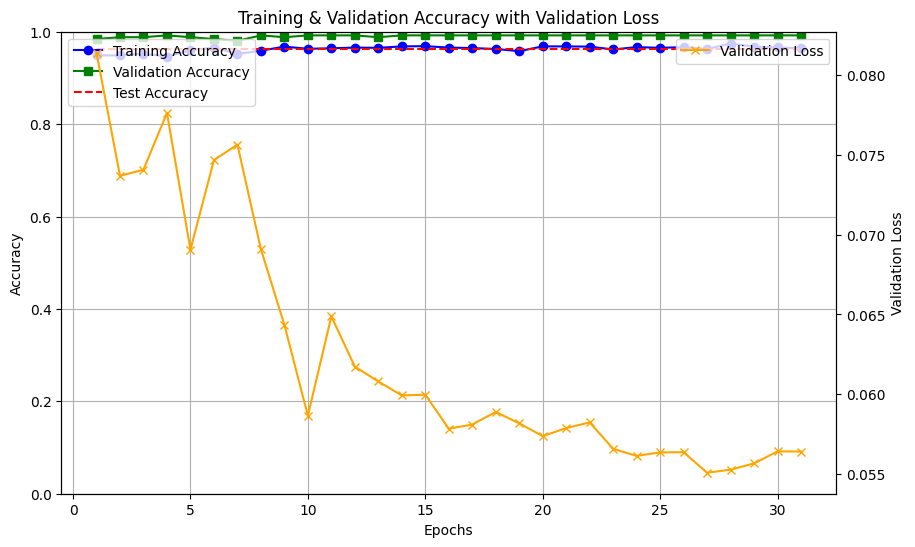

In [ ]:
import matplotlib.pyplot as plt

# 1️⃣ Get metrics from history
train_acc = history_2.history['accuracy']
val_acc = history_2.history['val_accuracy']
val_loss = history_2.history['val_loss']

# Number of epochs actually run
epochs_ran = len(train_acc)
epochs = range(1, epochs_ran + 1)

# 2️⃣ Create figure and twin y-axis
fig, ax1 = plt.subplots(figsize=(10,6))

# Accuracy lines on left y-axis
ax1.plot(epochs, train_acc, label='Training Accuracy', marker='o', color='blue')
ax1.plot(epochs, val_acc, label='Validation Accuracy', marker='s', color='green')
ax1.hlines(test_accuracy, xmin=1, xmax=epochs_ran, colors='red', linestyles='dashed', label='Test Accuracy')

ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1)
ax1.legend(loc='upper left')

# Loss line on right y-axis
ax2 = ax1.twinx()
ax2.plot(epochs, val_loss, label='Validation Loss', marker='x', color='orange')
ax2.set_ylabel('Validation Loss')
ax2.legend(loc='upper right')

# Title and grid
plt.title('Training & Validation Accuracy with Validation Loss')
ax1.grid(True)

plt.show()



**APPLICATION OF LOCAL INTERPRETABLE MODEL-AGNOSTIC EXPLANATIONS (LIME)**

Loading test data...
Found 106 images belonging to 4 classes.
Searching for image #10 of class 'diseased cotton plant'...
Found image! Explaining image with True Class: diseased cotton plant
Generating LIME explanation (this may take a moment)...


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 477ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 535ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 516ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 357ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

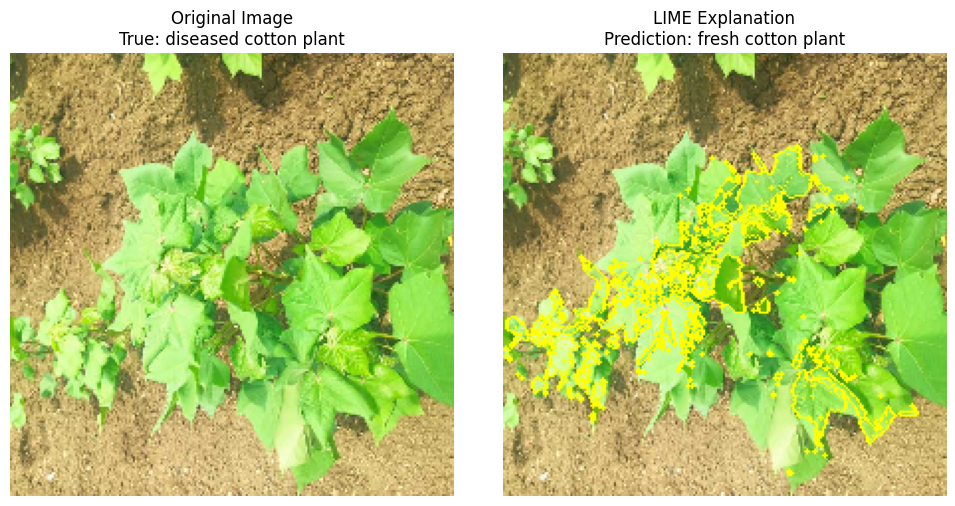

Explanation complete. Check the popup window for the plot.


In [ ]:
!pip install lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt

# -----------------------------
# Configuration
# -----------------------------
MODEL_PATH = 'model_efficientnet_final_optimized.h5'
TEST_DIR = r"/content/dataset/Cotton Disease/test"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


# -----------------------------
# Data Loading (For Visualization)
# -----------------------------
# We use a 'raw' generator for LIME to get interpretable images (0-255)
# This allows LIME's segmentation to work on actual pixels, not normalized values.
print("Loading test data...")
test_datagen_raw = ImageDataGenerator() # No preprocessing here!

test_generator_raw = test_datagen_raw.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True # Shuffle to get random images
)

# -----------------------------
# Prediction Function (The Bridge)
# -----------------------------
def predict_fn(images):
    """
    LIME passes 'images' as a numpy array of shape (batch, h, w, c).
    These images are in the range of the input provided to LIME (likely 0-255).
    We must preprocess them exactly as the model expects before predicting.
    """
    # 1. Ensure images are float32
    images = np.array(images, dtype=np.float32)

    # 2. Apply EfficientNet preprocessing
    # preprocess_input operates in-place or returns copy.
    # It handles the scaling (-1 to 1 or 0 to 255 depending on version).
    processed_images = preprocess_input(images.copy())

    # 3. Predict
    return model.predict(processed_images)

# -----------------------------
# Select an Image (Configuration)
# -----------------------------
# Change these values to select a specific image
TARGET_CLASS_NAME = 'diseased cotton plant' # Options: diseased cotton leaf, diseased cotton plant, fresh cotton leaf, fresh cotton plant
TARGET_INDEX =  10   #  for the 1st image of that class found, 1 for the 2nd, etc.

print(f"Searching for image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'...")

# Get class indices mapping
label_map = (test_generator_raw.class_indices)
label_map_inv = {v: k for k, v in label_map.items()}

if TARGET_CLASS_NAME not in label_map:
    print(f"Error: Class '{TARGET_CLASS_NAME}' not found. Available classes: {list(label_map.keys())}")
    exit()

target_class_idx = label_map[TARGET_CLASS_NAME]

# Scan the generator to find the target image
img_to_explain = None
true_label_idx = None
count = 0
found = False

# Reset generator to be sure
test_generator_raw.reset()

max_batches = len(test_generator_raw)
for i in range(max_batches):
    batch_images, batch_labels = next(test_generator_raw)

    # Iterate through batch
    for j in range(len(batch_images)):
        current_label_idx = np.argmax(batch_labels[j])

        if current_label_idx == target_class_idx:
            if count == TARGET_INDEX:
                img_to_explain = batch_images[j]
                true_label_idx = current_label_idx
                found = True
                break
            count += 1

    if found:
        break

if not found:
    print(f"Error: Could not find image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'. Found {count} images total.")
    exit()

print(f"Found image! Explaining image with True Class: {label_map_inv[true_label_idx]}")

# -----------------------------
# Run LIME
# -----------------------------
print("Generating LIME explanation (this may take a moment)...")
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    image=img_to_explain.astype('double'), # LIME likes double/float
    classifier_fn=predict_fn,
    top_labels=5,
    hide_color=0,
    num_samples=1000 # Increase for better quality, decrease for speed
)

# -----------------------------
# Get Explanation for Top Class
# -----------------------------
top_pred_class = explanation.top_labels[0]
print(f"Top Predicted Class: {label_map_inv[top_pred_class]}")

# Get image and mask for the top class
# positive_only=True shows only superpixels that contribute POSITIVELY to the class
temp, mask = explanation.get_image_and_mask(
    top_pred_class,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

# -----------------------------
# Visualize
# -----------------------------
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img_to_explain.astype('uint8'))
plt.title(f"Original Image\nTrue: {label_map_inv[true_label_idx]}")
plt.axis('off')

# LIME Explanation
plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp.astype('uint8'), mask))
plt.title(f"LIME Explanation\nPrediction: {label_map_inv[top_pred_class]}")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Explanation complete. Check the popup window for the plot.")
